<h1 align="center">Feature Selection</h1>

Inputs: the cleaned checkpoint from `data_cleaning.ipynb` (`dataset/cleaned_311.csv`).

In [1]:
import os
if not os.path.isdir('dataset') and os.path.isdir('../dataset'):
    os.chdir('..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

df = pd.read_csv('dataset/cleaned_311.csv', low_memory=False)
df['Created Date'] = pd.to_datetime(df['Created Date'])
print(df.shape)
df.head()

/usr/lib/python3/dist-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.17.3 and <1.25.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


(3759919, 10)


,Created Date,Problem (formerly Complaint Type),Problem Detail (formerly Descriptor),Agency,Borough,Location Type,Open Data Channel Type,Community Board,Police Precinct,resolution_hours
0,2026-09-20 01:39:36,noise - general,loud music/party,nypd,brooklyn,residential building,online,05 brooklyn,precinct 75,0.132222
1,2026-09-20 01:37:27,noise - general,loud music/party,nypd,brooklyn,street/sidewalk,mobile,01 brooklyn,precinct 94,0.166389
2,2026-09-20 01:36:25,noise - general,loud music/party,nypd,manhattan,park/playground,online,12 manhattan,precinct 33,0.149444
3,2026-09-20 01:35:40,noise - general,loud talking,nypd,brooklyn,street/sidewalk,mobile,08 brooklyn,precinct 77,0.230278
4,2026-09-20 01:34:30,noise - general,banging/pounding,nypd,manhattan,club/bar/restaurant,phone,03 manhattan,precinct 7,0.171944


### Time-based features

**`Created Date`** is the timestamp when the 311 request was filed (the start of the clock for resolution time). In the raw data it's text such as `09/20/2026 01:51:01 AM`; it's parsed to a datetime so pandas can extract parts of it. In the cleaned checkpoint it spans **2025-09-21 to 2026-09-20** with no missing values. It's the source for every time feature below, and the raw column itself is not used as a feature.

Derived features:
- `created_hour`: 1–24, with midnight as 24 (so 1 = 1 AM, 23 = 11 PM, 24 = midnight).
- `created_month`: 1–12.
- `day_of_week`: 1–7, where 1 = Monday and 7 = Sunday.
- `time_of_day`: night (0–5), morning (6–11), afternoon (12–17), evening (18–23).
- `is_weekend`: 1 for Saturday or Sunday.
- `season`: winter (12, 1, 2), spring (3, 4, 5), summer (6, 7, 8), fall (9, 10, 11).

Note: numeric hour treats 24 and 1 as far apart, even though they're neighbours on the clock. The time-of-day category avoids that issue, and we check both below.

Note: `season` is a coarser grouping of `created_month` — it's fully determined by it (Cramér's V = 1.0 between the two), the same relationship `time_of_day` has with `created_hour`. Keep whichever granularity is more useful, not both.

In [2]:
h = df['Created Date'].dt.hour
df['created_hour'] = h.where(h > 0, 24)
df['created_month'] = df['Created Date'].dt.month
df['day_of_week'] = df['Created Date'].dt.dayofweek + 1
df['time_of_day'] = pd.cut(h, bins=[-1, 5, 11, 17, 23], labels=['night', 'morning', 'afternoon', 'evening'])
df['is_weekend'] = (df['day_of_week'] >= 6).astype(int)

season_map = {12: 'winter', 1: 'winter', 2: 'winter', 3: 'spring', 4: 'spring', 5: 'spring',
              6: 'summer', 7: 'summer', 8: 'summer', 9: 'fall', 10: 'fall', 11: 'fall'}
df['season'] = df['created_month'].map(season_map)

df['log_resolution_hours'] = np.log1p(df['resolution_hours'])
df[['created_hour', 'created_month', 'day_of_week', 'time_of_day', 'is_weekend', 'season']].head()

,created_hour,created_month,day_of_week,time_of_day,is_weekend,season
0,1,9,7,night,1,fall
1,1,9,7,night,1,fall
2,1,9,7,night,1,fall
3,1,9,7,night,1,fall
4,1,9,7,night,1,fall


### Categorical features association (Cramér's V)

Association between the categorical features, to spot overlap before choosing which to keep.

**How it's calculated:**

1. **Build a contingency table** of counts for each pair of features (rows are categories of one feature, columns are categories of the other).

2. **Compute the chi-square statistic**, which compares observed counts $O$ with the counts $E$ expected if the two features were independent:

$$\chi^2 = \sum \frac{(O - E)^2}{E}, \qquad E = \frac{\text{row total} \times \text{column total}}{N}$$

3. **Scale it to 0–1:**

$$V = \sqrt{\frac{\chi^2 / N}{\min(r - 1,\ k - 1)}}$$


**Note:** with about 3.7 million rows, the chi-square test is significant for almost any pair, so the p-value is not useful for deciding what to keep. The size of $V$ is what matters.

For resolution hours (a continuous target), the categorical-to-target column uses the correlation ratio $\eta$ instead, which measures how much of the variance in log resolution time is explained by the category.

In [3]:
from scipy.stats import chi2_contingency

def cramers_v(a, b):
    ct = pd.crosstab(a, b)
    chi2 = chi2_contingency(ct)[0]
    n = ct.values.sum()
    r, k = ct.shape
    return np.sqrt((chi2 / n) / min(r - 1, k - 1))

def correlation_ratio(x, y):
    g = y.groupby(x)
    ss_between = (g.size() * (g.mean() - y.mean()) ** 2).sum()
    return np.sqrt(ss_between / ((y - y.mean()) ** 2).sum())

cols = ['Problem (formerly Complaint Type)', 'Agency', 'Location Type', 'Open Data Channel Type', 'time_of_day', 'is_weekend', 'season']
log_target = np.log1p(df['resolution_hours'])

cramer = pd.DataFrame(
    [[cramers_v(df[a], df[b]) for b in cols] for a in cols],
    index=cols, columns=cols,
)
# resolution hours is continuous, so categorical-to-target uses the correlation ratio (on log hours)
cramer['Resolution hours (η)'] = [correlation_ratio(df[a], log_target) for a in cols]
cramer = cramer.round(2)
cramer

/tmp/ipykernel_33937/2930965115.py:11: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  g = y.groupby(x)


,Problem (formerly Complaint Type),Agency,Location Type,Open Data Channel Type,time_of_day,is_weekend,season,Resolution hours (η)
Problem (formerly Complaint Type),1.00,0.79,0.69,0.54,0.22,0.20,0.22,0.83
Agency,0.79,1.00,0.56,0.47,0.15,0.14,0.12,0.76
Location Type,0.69,0.56,1.00,0.42,0.13,0.11,0.11,0.56
Open Data Channel Type,0.54,0.47,0.42,1.00,0.09,0.09,0.05,0.36
time_of_day,0.22,0.15,0.13,0.09,1.00,0.12,0.02,0.20
is_weekend,0.20,0.14,0.11,0.09,0.12,1.00,0.02,0.10
season,0.22,0.12,0.11,0.05,0.02,0.02,1.00,0.09


***Findings:***
- **Complaint type overlaps with agency (0.79) and location type (0.69), but this is not the same as redundancy.** A Cramér's V of 0.79 is high but well below 1.0
- **Agency and location type also overlap (0.56).**
- **Open data channel is only moderately related to the others** (0.42 to 0.54), so it adds some independent information.
- **Time of day is almost independent of the other categorical features** (0.09 to 0.22). It's a useful, non-redundant addition.
- **Against resolution hours (η):** complaint type 0.83, agency 0.76, location type 0.56, open data channel 0.36, time of day 0.20. Complaint type and agency are the strongest predictors of resolution time.

### Correlation matrix (numerical features)

Spearman correlation between the numeric features and the target (`resolution_hours`). Spearman is used because the target is heavily skewed, and it measures rank-based association.

In [4]:
num_cols = ['created_hour', 'created_month', 'day_of_week', 'resolution_hours']
numeric_corr = df[num_cols].corr(method='spearman').round(3)
numeric_corr

,created_hour,created_month,day_of_week,resolution_hours
created_hour,1.000,0.001,0.042,-0.082
created_month,0.001,1.000,-0.000,-0.055
day_of_week,0.042,-0.000,1.000,-0.085
resolution_hours,-0.082,-0.055,-0.085,1.000


***Findings:***
- **The time features are almost uncorrelated with each other** (|r| ≤ 0.04), so they don't overlap. Each carries its own information.
- **Each time feature is weakly related to resolution time:** hour (-0.08), day of week (-0.09), and month (-0.06). Complaints filed later in the day or week resolve slightly faster, but the effect is small.

### Final feature set

/tmp/ipykernel_33937/2930965115.py:11: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  g = y.groupby(x)
/tmp/ipykernel_33937/2930965115.py:11: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  g = y.groupby(x)


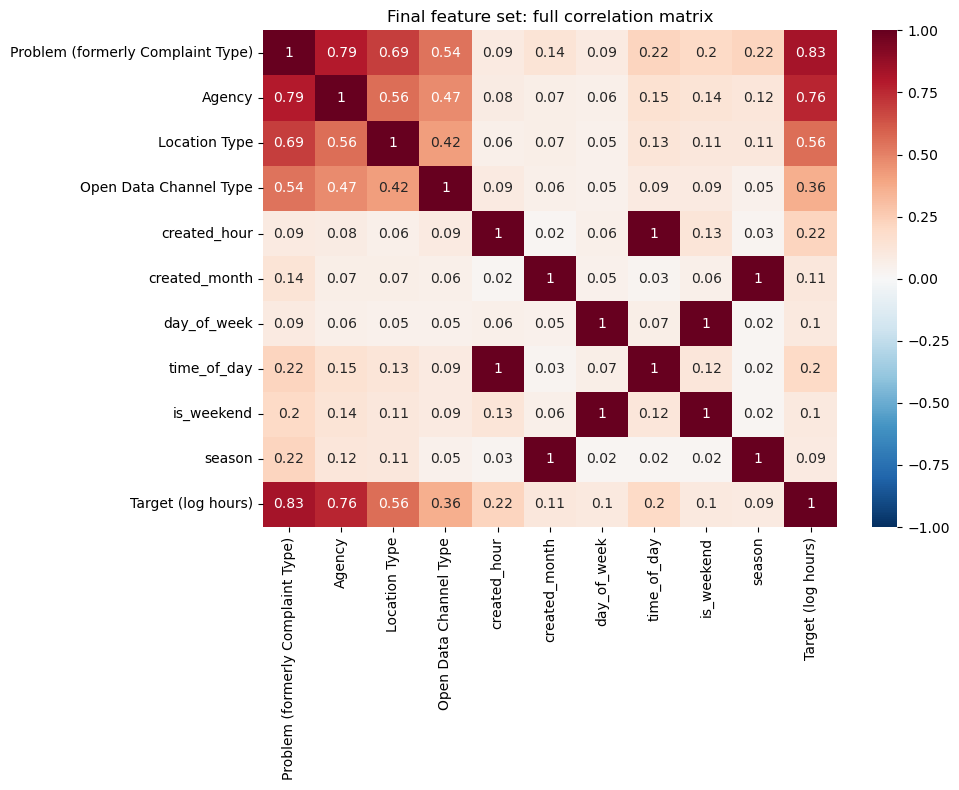

In [5]:
final_features = [
    'Problem (formerly Complaint Type)', 'Agency', 'Location Type', 'Open Data Channel Type',
    'created_hour', 'created_month', 'day_of_week', 'time_of_day', 'is_weekend', 'season',
]
# All of these are discrete/categorical codes (even the int-typed ones: hour-of-day, month-of-year,
# day-of-week), not continuous measurements - treating them by dtype alone misses that and sends
# deterministic pairs like (season, created_month) through correlation_ratio instead of cramers_v.
cat_features = final_features
num_features = []
names = cat_features + num_features + ['Target (log hours)']
log_target = df['log_resolution_hours']

full_matrix = pd.DataFrame(np.nan, index=names, columns=names)
for a in names:
    for b in names:
        if a == b:
            full_matrix.loc[a, b] = 1.0
            continue
        a_cat, b_cat = a in cat_features, b in cat_features
        a_col = log_target if a == 'Target (log hours)' else df[a]
        b_col = log_target if b == 'Target (log hours)' else df[b]
        if a_cat and b_cat:
            full_matrix.loc[a, b] = cramers_v(a_col, b_col)
        elif not a_cat and not b_cat:
            full_matrix.loc[a, b] = a_col.corr(b_col, method='spearman')
        else:
            cat_col, num_col = (a_col, b_col) if a_cat else (b_col, a_col)
            full_matrix.loc[a, b] = correlation_ratio(cat_col, num_col)

full_matrix = full_matrix.round(2)

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(full_matrix, annot=True, cmap='RdBu_r', vmin=-1, vmax=1, ax=ax)
ax.set_title('Final feature set: full correlation matrix')
plt.tight_layout()
plt.show()

In [6]:
features = [
    'Problem (formerly Complaint Type)',
    'Agency',
    'Location Type',
    'Open Data Channel Type',
    'time_of_day',
    'is_weekend',
    'season',
]
target = 'resolution_hours'

model_df = df[features + [target]]
print(f"Features: {len(features)}  |  Rows: {len(model_df):,}")
print(model_df[features].nunique())

model_df.to_csv('dataset/model_features.csv', index=False)
print("\nSaved dataset/model_features.csv")

Features: 7  |  Rows: 3,759,919
Problem (formerly Complaint Type)    73
Agency                               16
Location Type                        22
Open Data Channel Type                5
time_of_day                           4
is_weekend                            2
season                                4
dtype: int64

Saved dataset/model_features.csv


***Findings:*** dropped `created_hour`, `created_month`, and `day_of_week` from the 10-feature set
- `time_of_day` kept over `created_hour`
- `season` kept over `created_month` 
- `is_weekend` kept over `day_of_week`

Final set: `Problem (formerly Complaint Type)`, `Agency`, `Location Type`, `Open Data Channel Type`, `time_of_day`, `is_weekend`, `season` — 7 features, saved to `dataset/model_features.csv`.

### Encoding categorical variables

6 of the 7 final features are categorical (`Problem (formerly Complaint Type)`, `Agency`, `Location Type`, `Open Data Channel Type`, `time_of_day`, `season`); `is_weekend` is already 0/1.

**Label/ordinal encoding** (`sklearn.preprocessing.OrdinalEncoder`): each category becomes a single integer (e.g. `nypd` → 3)

**Three-way split:** train (60%) / validation (20%) / test (20%)

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder

categorical_cols = ['Problem (formerly Complaint Type)', 'Agency', 'Location Type', 'Open Data Channel Type', 'time_of_day', 'season']
numeric_cols = ['is_weekend']
encoded_features = categorical_cols + numeric_cols

X = model_df[encoded_features]
y = model_df['resolution_hours']

# First peel off test (20%), then split what's left into train (60%) and validation (20%)
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.4, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

print(f"Train: {X_train.shape} ({len(X_train)/len(X)*100:.0f}%)")
print(f"Val:   {X_val.shape} ({len(X_val)/len(X)*100:.0f}%)")
print(f"Test:  {X_test.shape} ({len(X_test)/len(X)*100:.0f}%)")

Train: (2255951, 7) (60%)
Val:   (751984, 7) (20%)
Test:  (751984, 7) (20%)


In [8]:
encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)

X_train = X_train.copy()
X_val = X_val.copy()
X_test = X_test.copy()
X_train[categorical_cols] = encoder.fit_transform(X_train[categorical_cols])
X_val[categorical_cols] = encoder.transform(X_val[categorical_cols])
X_test[categorical_cols] = encoder.transform(X_test[categorical_cols])

print(f"Unknown-category cells in val:  {(X_val[categorical_cols] == -1).sum().sum()}")
print(f"Unknown-category cells in test: {(X_test[categorical_cols] == -1).sum().sum()}")
X_train.head()

Unknown-category cells in val:  0
Unknown-category cells in test: 0


,Problem (formerly Complaint Type),Agency,Location Type,Open Data Channel Type,time_of_day,season,is_weekend
3084049,32.0,12.0,18.0,0.0,2.0,0.0,0
3021113,0.0,12.0,8.0,1.0,2.0,3.0,0
2222533,32.0,12.0,18.0,3.0,3.0,3.0,0
411252,5.0,12.0,18.0,1.0,2.0,2.0,0
3118912,42.0,12.0,11.0,1.0,0.0,0.0,1


In [9]:
import joblib

# Checkpoint for the modeling notebook. dataset/*.csv and *.joblib are git-ignored, so this stays local.
X_train.to_csv('dataset/X_train_encoded.csv', index=False)
X_val.to_csv('dataset/X_val_encoded.csv', index=False)
X_test.to_csv('dataset/X_test_encoded.csv', index=False)
y_train.to_csv('dataset/y_train.csv', index=False)
y_val.to_csv('dataset/y_val.csv', index=False)
y_test.to_csv('dataset/y_test.csv', index=False)
joblib.dump(encoder, 'dataset/ordinal_encoder.joblib')

print("Saved: X_train_encoded.csv, X_val_encoded.csv, X_test_encoded.csv, y_train.csv, y_val.csv, y_test.csv, ordinal_encoder.joblib")

Saved: X_train_encoded.csv, X_val_encoded.csv, X_test_encoded.csv, y_train.csv, y_val.csv, y_test.csv, ordinal_encoder.joblib
